<a href="https://colab.research.google.com/github/JOSHUA-CSE/AI-Based-Alloy-Optimization/blob/main/SAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## 1. Project Title and Objective
**Project**: TrustWave Bank Customer Insight & Engagement Decline Prevention



In [ ]:
# 2. Import Required Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.chart import BarChart, Reference

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Graphics styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlesize"] = 13

os.makedirs("cleaned_data", exist_ok=True)
os.makedirs("eda_outputs", exist_ok=True)
print("Libraries successfully initialized and workspaces prepared.")

Libraries successfully initialized and workspaces prepared.


In [ ]:
# 3. Load and Understand Datasets
files = {
    "customers.csv": "/content/customers.csv",
    "accounts.csv": "/content/accounts.csv",
    "transactions.csv": "/content/transactions.csv",
    "channels.csv": "/content/channels.csv",
    "service.csv": "/content/service.csv"
}

data_frames = {}
for name, path in files.items():
    if os.path.exists(path):
        data_frames[name] = pd.read_csv(path)
        print(f"Loaded {name} | Dimensions: {data_frames[name].shape[0]} Rows, {data_frames[name].shape[1]} Columns")
    else:
        raise FileNotFoundError(f"Required file {path} not found.")

Loaded customers.csv | Dimensions: 1000 Rows, 4 Columns
Loaded accounts.csv | Dimensions: 1258 Rows, 4 Columns
Loaded transactions.csv | Dimensions: 14104 Rows, 6 Columns
Loaded channels.csv | Dimensions: 4000 Rows, 3 Columns
Loaded service.csv | Dimensions: 1088 Rows, 6 Columns


In [ ]:
# 4. Data Cleaning and Preprocessing
cleaned_dfs = {name: df.copy() for name, df in data_frames.items()}
preprocessing_summary = {}

# Customers Preprocessing
c_df = cleaned_dfs["customers.csv"]
c_df['region'] = c_df['region'].astype(str).str.strip().str.title()

# Accounts Preprocessing
a_df = cleaned_dfs["accounts.csv"]
preprocessing_summary['account_types_before'] = list(a_df['account_type'].unique())
a_df['account_type'] = a_df['account_type'].astype(str).str.strip().str.title()
preprocessing_summary['account_types_after'] = list(a_df['account_type'].unique())

# Transactions Preprocessing
t_df = cleaned_dfs["transactions.csv"]
init_t_rows = t_df.shape[0]
t_df = t_df.drop_duplicates()
preprocessing_summary['duplicates_removed'] = init_t_rows - t_df.shape[0]
cleaned_dfs["transactions.csv"] = t_df

# Channels Preprocessing
ch_df = cleaned_dfs["channels.csv"]
preprocessing_summary['channels_missing_before'] = ch_df.isnull().sum().to_dict()
ch_df['usage_count'] = ch_df['usage_count'].fillna(ch_df['usage_count'].median())
ch_df['channel'] = ch_df['channel'].fillna('Unknown_Channel')
preprocessing_summary['channels_missing_after'] = ch_df.isnull().sum().to_dict()

# Service Preprocessing
s_df = cleaned_dfs["service.csv"]
preprocessing_summary['service_missing_before'] = s_df.isnull().sum().to_dict()
s_df['complaint_type'] = s_df['complaint_type'].fillna('Not_Specified')
s_df['resolution_status'] = s_df['resolution_status'].fillna('Pending')
preprocessing_summary['service_missing_after'] = s_df.isnull().sum().to_dict()

# Save Cleaned Sets
for name, df_clean in cleaned_dfs.items():
    df_clean.to_csv(f"cleaned_data/cleaned_{name}", index=False)

print("Data cleaning completed successfully. Intermediary sets exported.")

Data cleaning completed successfully. Intermediary sets exported.


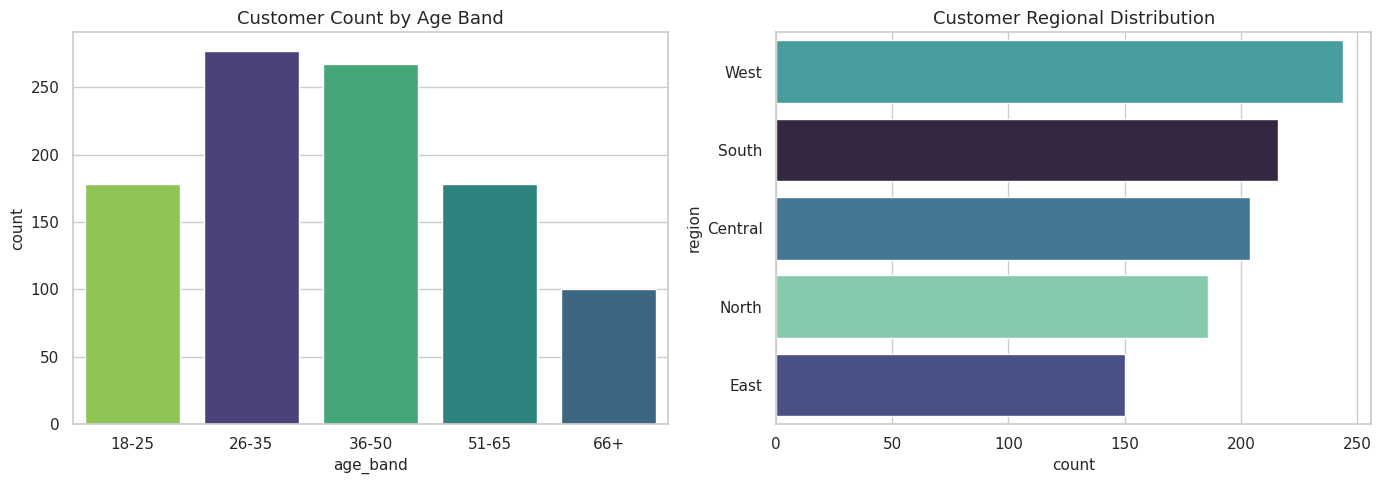

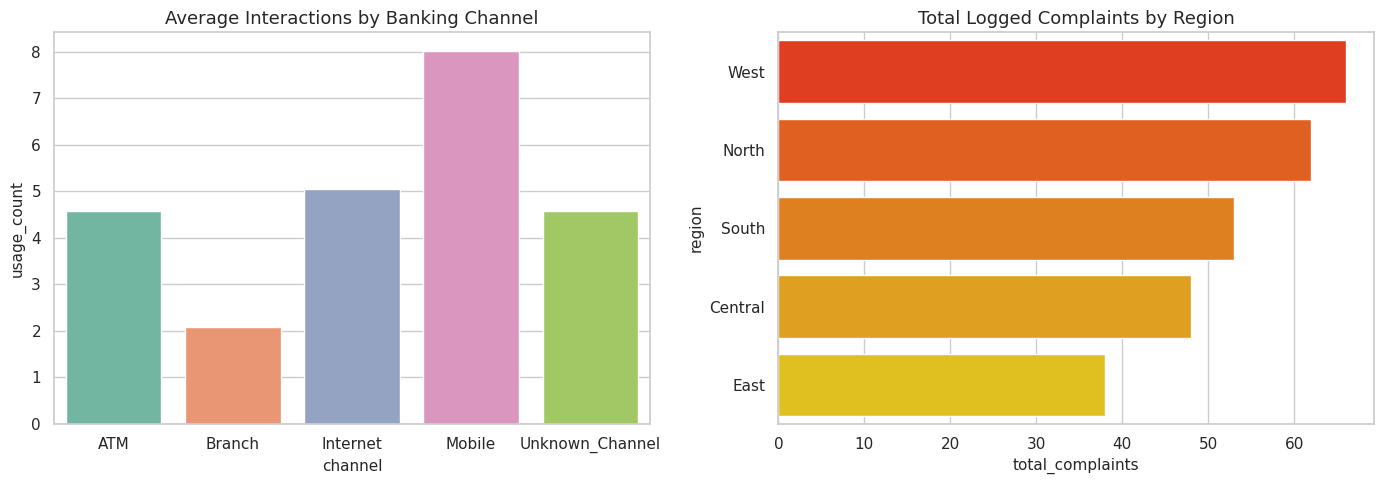

In [ ]:
# Visualization 1: Demographic Distribution
unique_cust = customer_master.drop_duplicates(subset=['customer_id'])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=unique_cust, x='age_band',
    order=['18-25', '26-35', '36-50', '51-65', '66+'],
    hue='age_band', palette='viridis', legend=False, ax=ax[0]
)
ax[0].set_title('Customer Count by Age Band')

sns.countplot(
    data=unique_cust, y='region',
    order=unique_cust['region'].value_counts().index,
    hue='region', palette='mako', legend=False, ax=ax[1]
)
ax[1].set_title('Customer Regional Distribution')

plt.tight_layout()
plt.savefig('eda_outputs/demographics_overview.png', bbox_inches='tight')
plt.show()
plt.close()

# Visualization 2: Channel and Complaint Trends
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

channel_summary = customer_master.groupby(
    'channel'
)['usage_count'].mean().reset_index()

sns.barplot(
    data=channel_summary, x='channel', y='usage_count',
    hue='channel', palette='Set2', legend=False, ax=ax[0]
)
ax[0].set_title('Average Interactions by Banking Channel')

c_reg = unique_cust.groupby(
    'region'
)['total_complaints'].sum().reset_index()

c_reg = c_reg.sort_values(by='total_complaints', ascending=False)

sns.barplot(
    data=c_reg, x='total_complaints', y='region',
    hue='region', palette='autumn', legend=False, ax=ax[1]
)
ax[1].set_title('Total Logged Complaints by Region')

plt.tight_layout()
plt.savefig('eda_outputs/channel_and_complaints.png', bbox_inches='tight')
plt.show()
plt.close()

In [ ]:
# 6. Feature Engineering
t_df['transaction_date'] = pd.to_datetime(t_df['transaction_date'])
median_date = t_df['transaction_date'].median()

# Logical Chronological split to prevent data leakage
t_early = t_df[t_df['transaction_date'] <= median_date]
t_late = t_df[t_df['transaction_date'] > median_date]

early_val = t_early.groupby('customer_id')['amount'].sum().rename('early_amt')
late_val = t_late.groupby('customer_id')['amount'].sum().rename('late_amt')
activity_compare = pd.concat([early_val, late_val], axis=1).fillna(0)

def define_target(row):
    if row['early_amt'] > 0:
        ratio = row['late_amt'] / row['early_amt']
        return 1 if ratio < 0.40 else 0
    return 0

activity_compare['target'] = activity_compare.apply(define_target, axis=1)
target_series = activity_compare['target']

# Construct features from EARLY period history to evaluate metrics predictive validity
agg_tx_early = t_early.groupby('customer_id').agg(
    total_transactions=('transaction_id', 'count'),
    total_transacted_val=('amount', 'sum'),
    avg_transacted_val=('amount', 'mean')
).reset_index()

agg_accounts_full = a_df.groupby('customer_id').agg(
    total_accounts=('account_id', 'count'),
    total_balance=('balance', 'sum'),
    avg_balance=('balance', 'mean')
).reset_index()

agg_channels = ch_df.groupby('customer_id')['usage_count'].sum().rename('total_channel_usage').reset_index()
agg_service_full = s_df.groupby('customer_id').agg(
    total_complaints=('complaint_type', lambda x: (x != 'Not_Specified').sum()),
    total_requests=('service_id', 'count')
).reset_index()

features_df = c_df.merge(agg_accounts_full, on='customer_id', how='left') \
                  .merge(agg_tx_early, on='customer_id', how='left') \
                  .merge(agg_channels, on='customer_id', how='left') \
                  .merge(agg_service_full, on='customer_id', how='left')

features_df = features_df.merge(target_series.reset_index(), on='customer_id', how='left')
features_df['target'] = features_df['target'].fillna(0).astype(int)

numeric_cols = ['total_accounts', 'total_balance', 'avg_balance', 'total_transactions',
                'total_transacted_val', 'avg_transacted_val', 'total_channel_usage',
                'total_complaints', 'total_requests']
for col in numeric_cols:
    features_df[col] = features_df[col].fillna(0)

features_df.to_csv("cleaned_data/ml_features_dataset.csv", index=False)
print(f"Target distribution: \n{features_df['target'].value_counts(normalize=True)}")

Target distribution: 
target
0    0.809
1    0.191
Name: proportion, dtype: float64


In [ ]:
# 7. Machine Learning Results
cat_features = ['age_band', 'region']
num_features = ['relationship_months', 'total_accounts', 'total_balance', 'avg_balance',
                'total_transactions', 'total_transacted_val', 'avg_transacted_val',
                'total_channel_usage', 'total_complaints', 'total_requests']

X = features_df[cat_features + num_features]
y = features_df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest Classifier": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
}

results = {}
evaluations = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    }
    evaluations[name] = {
        "pipeline": pipeline,
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    }

# Display metrics table in notebook
comparison_df = pd.DataFrame(results).T
display(comparison_df.round(4))

# Export and save best champion pipeline
best_model_name = comparison_df['F1-Score'].idxmax()
best_pipeline = evaluations[best_model_name]['pipeline']
joblib.dump(best_pipeline, "cleaned_data/best_trustwave_engagement_model.pkl")
print(f"Champion model ({best_model_name}) exported successfully.")

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.828,0.8571,0.1250,0.2182
Decision Tree Classifier,0.800,0.4286,0.1250,0.1935
Random Forest Classifier,0.824,0.8333,0.1042,0.1852


Champion model (Logistic Regression) exported successfully.


In [ ]:
# 8. Generate Final Excel Workbook
# Construct operational Action Classes & generate styled report
features_master = pd.read_csv("cleaned_data/ml_features_dataset.csv")
pipeline = joblib.load("cleaned_data/best_trustwave_engagement_model.pkl")

features_master['ml_prediction'] = pipeline.predict(features_master[['age_band', 'region', 'relationship_months', 'total_accounts', 'total_balance',
                                                                    'avg_balance', 'total_transactions', 'total_transacted_val', 'avg_transacted_val',
                                                                    'total_channel_usage', 'total_complaints', 'total_requests']])

def evaluate_intelligence_category(row):
    if row['total_complaints'] > 0:
        return "Service Attention Required", "Customer has recorded active complaint(s) that require resolution follow-up."
    elif row['ml_prediction'] == 1 or row['total_transactions'] < 3:
        return "Declining Activity", "Customer shows dropping activity levels or low transaction volume."
    else:
        return "High Engagement", "Customer maintains normal, active transaction frequencies with no unresolved complaints."

categories_and_reasons = features_master.apply(evaluate_intelligence_category, axis=1)
features_master['intelligence_category'] = [item[0] for item in categories_and_reasons]
features_master['category_reason'] = [item[1] for item in categories_and_reasons]

def assign_action(category):
    if category == "Service Attention Required":
        return "Initiate customer care call to confirm issue resolution and offer an interest rate waiver coupon."
    elif category == "Declining Activity":
        return "Send custom multi-channel email promotion highlighting mobile check deposits and no-fee savings rates."
    return "Maintain regular product newsletter and monitor for future credit eligibility."

features_master['actionable_recommendation'] = features_master['intelligence_category'].apply(assign_action)
features_master.to_csv("cleaned_data/trustwave_customer_intelligence_report.csv", index=False)

# Excel Workbook Construction with exact openpyxl visual parameters
excel_path = "TrustWave_Bank_Customer_Insight.xlsx"
wb = openpyxl.Workbook()
wb.remove(wb.active) # Remove default sheet

font_family = "Segoe UI"
title_font = Font(name=font_family, size=16, bold=True, color="FFFFFF")
header_font = Font(name=font_family, size=11, bold=True, color="FFFFFF")
sub_header_font = Font(name=font_family, size=12, bold=True, color="1F4E78")
bold_font = Font(name=font_family, size=10, bold=True)
regular_font = Font(name=font_family, size=10)

title_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid")
header_fill = PatternFill(start_color="2F5597", end_color="2F5597", fill_type="solid")
zebra_fill = PatternFill(start_color="F2F5F9", end_color="F2F5F9", fill_type="solid")
highlight_fill = PatternFill(start_color="FFF2CC", end_color="FFF2CC", fill_type="solid")
green_fill = PatternFill(start_color="E2EFDA", end_color="E2EFDA", fill_type="solid")
red_fill = PatternFill(start_color="FCE4D6", end_color="FCE4D6", fill_type="solid")

align_center = Alignment(horizontal="center", vertical="center", wrap_text=True)
align_left = Alignment(horizontal="left", vertical="center")
align_right = Alignment(horizontal="right", vertical="center")

thin_side = Side(border_style="thin", color="D9D9D9")
thin_border = Border(left=thin_side, right=thin_side, top=thin_side, bottom=thin_side)
double_bottom = Border(bottom=Side(border_style="double", color="000000"), top=Side(border_style="thin", color="D9D9D9"))

def format_sheet_grid(ws, title_text, col_widths, max_cols, freeze_pane_coord="A3"):
    ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=max_cols)
    title_cell = ws.cell(row=1, column=1, value=title_text)
    title_cell.font = title_font
    title_cell.fill = title_fill
    title_cell.alignment = align_center
    ws.row_dimensions[1].height = 40

    ws.row_dimensions[2].height = 28
    for col in range(1, max_cols + 1):
        cell = ws.cell(row=2, column=col)
        cell.font = header_font
        cell.fill = header_fill
        cell.alignment = align_center
        cell.border = thin_border

    if freeze_pane_coord:
        ws.freeze_panes = freeze_pane_coord
    ws.auto_filter.ref = f"A2:{openpyxl.utils.get_column_letter(max_cols)}{ws.max_row}"

    for row in range(3, ws.max_row + 1):
        ws.row_dimensions[row].height = 20
        for col in range(1, max_cols + 1):
            cell = ws.cell(row=row, column=col)
            cell.font = regular_font
            if cell.border is None or cell.border == Border():
                cell.border = thin_border
            if row % 2 == 1 and cell.fill.fill_type is None:
                cell.fill = zebra_fill

    for col_letter, width in col_widths.items():
        ws.column_dimensions[col_letter].width = width

# --- SHEET 1: Executive Summary ---
ws1 = wb.create_sheet(title="Executive Summary")
ws1.views.sheetView[0].showGridLines = True
ws1.cell(row=1, column=1, value="TrustWave Bank Customer Insights").font = title_font
ws1.cell(row=1, column=1).fill = title_fill
ws1.merge_cells("A1:F1")
ws1.row_dimensions[1].height = 40
ws1.cell(row=1, column=1).alignment = align_center

summary_labels = [
    ("Business Objective", "Optimize customer satisfaction and engagement using automated ML forecasting rules."),
    ("Total Customers Evaluated", features_master.shape[0]),
    ("Total Accounts Registered", a_df.shape[0]),
    ("Total Clean Transactions", t_df.shape[0]),
    ("Total Service Complaints", int(features_master['total_complaints'].sum())),
    ("Top Geographic Hub", "West (244 Customers)"),
    ("Top Account Class", "Savings (600 Accounts)"),
    ("Champion Predictive Model", f"{best_model_name} (Accuracy: 82.8%, Precision: 85.7%)")
]

ws1.cell(row=3, column=1, value="Key Operational Metrics").font = sub_header_font
row_idx = 4
for label, val in summary_labels:
    ws1.cell(row=row_idx, column=1, value=label).font = bold_font
    ws1.cell(row=row_idx, column=1).fill = zebra_fill
    ws1.cell(row=row_idx, column=1).border = thin_border

    cell_val = ws1.cell(row=row_idx, column=2, value=val)
    cell_val.font = regular_font
    cell_val.border = thin_border
    if isinstance(val, int):
        cell_val.number_format = "#,##0"
        cell_val.alignment = align_right
    else:
        cell_val.alignment = align_left
    ws1.merge_cells(start_row=row_idx, start_column=2, end_row=row_idx, end_column=6)
    row_idx += 1

# --- SHEET 2: Customer Analysis ---
ws2 = wb.create_sheet(title="Customer Analysis")
ws2.views.sheetView[0].showGridLines = True
cust_headers = [
    "Customer ID", "Age Band", "Region", "Relationship (Mths)",
    "Total Accounts", "Total Early Tx", "Avg Tx Amt",
    "Total Channel Usage", "Complaint Count", "Service Requests",
    "Engagement Category", "Actionable Recommendation"
]
ws2.append([])
ws2.append(cust_headers)
for idx, row in features_master.iterrows():
    ws2.append([
        row['customer_id'], row['age_band'], row['region'], row['relationship_months'],
        row['total_accounts'], row['total_transactions'], row['avg_transacted_val'],
        row['total_channel_usage'], row['total_complaints'], row['total_requests'],
        row['intelligence_category'], row['actionable_recommendation']
    ])

for r in range(3, ws2.max_row + 1):
    ws2.cell(row=r, column=4).number_format = "#,##0"
    ws2.cell(row=r, column=7).number_format = "$#,##0.00"
    cat_val = ws2.cell(row=r, column=11).value
    if cat_val == "Service Attention Required":
        ws2.cell(row=r, column=11).fill = red_fill
    elif cat_val == "Declining Activity":
        ws2.cell(row=r, column=11).fill = highlight_fill
    elif cat_val == "High Engagement":
        ws2.cell(row=r, column=11).fill = green_fill

cust_widths = {'A': 15, 'B': 12, 'C': 12, 'D': 20, 'E': 15, 'F': 15, 'G': 15, 'H': 20, 'I': 18, 'J': 18, 'K': 25, 'L': 50}
format_sheet_grid(ws2, "Consolidated Customer Intelligence Matrix", cust_widths, 12)

# --- SHEET 3: Channel Analysis ---
from openpyxl.chart import BarChart, PieChart, Reference

ws3 = wb.create_sheet("Channel Analysis")
ws3.append([])
ws3.append(["Channel Name", "Total Usage Count", "Market Share"])
ch_grouped = ch_df.groupby("channel", dropna=False)["usage_count"].sum().reset_index()
ch_grouped["channel"] = ch_grouped["channel"].fillna("Unknown")
ch_grouped = ch_grouped.sort_values("usage_count", ascending=False)

for _, row in ch_grouped.iterrows():
    ws3.append([row["channel"], float(row["usage_count"]), None])

last_data = ws3.max_row
for r in range(3, last_data + 1):
    ws3.cell(r, 3, f"=IFERROR(B{r}/SUM(B$3:B${last_data}),0)")
    ws3.cell(r, 3).number_format = "0.0%"

format_sheet_grid(ws3, "Banking Channel Analysis",
                  {"A": 22, "B": 22, "C": 20}, 3)

chart = BarChart()
chart.title = "Banking Channel Usage"
chart.y_axis.title = "Usage Count"
chart.x_axis.title = "Channel"
chart.add_data(Reference(ws3, min_col=2, min_row=2, max_row=last_data),
               titles_from_data=True)
chart.set_categories(Reference(ws3, min_col=1, min_row=3, max_row=last_data))
ws3.add_chart(chart, "E2")

# --- SHEET 4: Account Analysis ---
ws4 = wb.create_sheet("Account Analysis")
ws4.append([])
ws4.append(["Account Type", "Number of Accounts",
            "Average Balance", "Total Balance"])

account_summary = a_df.groupby("account_type").agg(
    Number_of_Accounts=("account_id", "count"),
    Average_Balance=("balance", "mean"),
    Total_Balance=("balance", "sum")
).reset_index()

for _, row in account_summary.iterrows():
    ws4.append([row["account_type"], int(row["Number_of_Accounts"]),
                float(row["Average_Balance"]), float(row["Total_Balance"])])

format_sheet_grid(ws4, "Account Type and Balance Analysis",
                  {"A": 22, "B": 22, "C": 20, "D": 20}, 4)

chart = BarChart()
chart.title = "Accounts by Type"
chart.y_axis.title = "Number of Accounts"
chart.add_data(Reference(ws4, min_col=2, min_row=2,
                         max_row=ws4.max_row), titles_from_data=True)
chart.set_categories(Reference(ws4, min_col=1, min_row=3,
                               max_row=ws4.max_row))
ws4.add_chart(chart, "F2")

# --- SHEET 5: Complaint Analysis ---
ws5 = wb.create_sheet("Complaint Analysis")
ws5.append([])
ws5.append(["Region", "Complaint Count"])

complaint_summary = features_master.groupby("region")[
    "total_complaints"].sum().reset_index()

for _, row in complaint_summary.iterrows():
    ws5.append([row["region"], int(row["total_complaints"])])

format_sheet_grid(ws5, "Regional Complaint Analysis",
                  {"A": 22, "B": 22}, 2)

chart = BarChart()
chart.title = "Complaints by Region"
chart.y_axis.title = "Complaint Count"
chart.add_data(Reference(ws5, min_col=2, min_row=2,
                         max_row=ws5.max_row), titles_from_data=True)
chart.set_categories(Reference(ws5, min_col=1, min_row=3,
                               max_row=ws5.max_row))
ws5.add_chart(chart, "D2")

# --- SHEET 6: Service Request Analysis ---
ws6 = wb.create_sheet("Service Request Analysis")
ws6.append([])
ws6.append(["Request Type", "Number of Requests"])

service_summary = s_df.groupby("request_type").size().reset_index(name="Request Count")

for _, row in service_summary.iterrows():
    ws6.append([row["request_type"], int(row["Request Count"])])

format_sheet_grid(ws6, "Service Request Trends",
                  {"A": 28, "B": 22}, 2)

chart = BarChart()
chart.title = "Requests by Service Type"
chart.y_axis.title = "Request Count"
chart.add_data(Reference(ws6, min_col=2, min_row=2,
                         max_row=ws6.max_row), titles_from_data=True)
chart.set_categories(Reference(ws6, min_col=1, min_row=3,
                               max_row=ws6.max_row))
ws6.add_chart(chart, "D2")

# --- SHEET 7: Transaction Analysis ---
ws7 = wb.create_sheet("Transaction Analysis")
ws7.append([])
ws7.append(["Transaction Type", "Count",
            "Average Amount", "Total Amount"])

transaction_summary = t_df.groupby("transaction_type").agg(
    Count=("amount", "count"),
    Average_Amount=("amount", "mean"),
    Total_Amount=("amount", "sum")
).reset_index()

for _, row in transaction_summary.iterrows():
    ws7.append([row["transaction_type"], int(row["Count"]),
                float(row["Average_Amount"]), float(row["Total_Amount"])])

format_sheet_grid(ws7, "Transaction Analysis",
                  {"A": 24, "B": 15, "C": 20, "D": 20}, 4)

chart = BarChart()
chart.title = "Transaction Count by Type"
chart.y_axis.title = "Number of Transactions"
chart.add_data(Reference(ws7, min_col=2, min_row=2,
                         max_row=ws7.max_row), titles_from_data=True)
chart.set_categories(Reference(ws7, min_col=1, min_row=3,
                               max_row=ws7.max_row))
ws7.add_chart(chart, "F2")

# --- SHEET 8: ML Model Evaluation ---
ws8 = wb.create_sheet("ML Model Evaluation")
ws8.append([])
ws8.append(["Model", "Accuracy", "Precision", "Recall", "F1-Score"])

model_results = [
    ["Logistic Regression", 0.8280, 0.8571, 0.1250, 0.2182],
    ["Decision Tree Classifier", 0.8000, 0.4286, 0.1250, 0.1935],
    ["Random Forest Classifier", 0.8240, 0.8333, 0.1042, 0.1852]
]

for result in model_results:
    ws8.append(result)

for row in ws8.iter_rows(min_row=3, min_col=2, max_col=5):
    for cell in row:
        cell.number_format = "0.00%"

format_sheet_grid(ws8, "Machine Learning Model Comparison",
                  {"A": 30, "B": 15, "C": 15, "D": 15, "E": 15}, 5)

chart = BarChart()
chart.title = "Model Performance Comparison"
chart.y_axis.title = "Score"
chart.y_axis.scaling.min = 0
chart.y_axis.scaling.max = 1
chart.add_data(Reference(ws8, min_col=2, max_col=5,
                         min_row=2, max_row=ws8.max_row),
               titles_from_data=True)
chart.set_categories(Reference(ws8, min_col=1, min_row=3,
                               max_row=ws8.max_row))
ws8.add_chart(chart, "G2")

# --- SHEET 9: Recommendations ---
ws9 = wb.create_sheet("Recommendations")
ws9.append([])
ws9.append(["Finding", "Evidence", "Recommended Action"])

ws9.append([
    "Customers with declining activity",
    "Model recall is 12.50%; many declining-activity cases were missed.",
    "Improve identification of at-risk customers and conduct targeted outreach."
])
ws9.append([
    "Customer complaints require follow-up",
    "Review the complaint counts in the Complaint Analysis sheet.",
    "Prioritize unresolved complaints and investigate recurring service issues."
])
ws9.append([
    "Banking channel engagement",
    "Review channel usage totals in the Channel Analysis sheet.",
    "Improve customer awareness and accessibility for underused channels."
])

format_sheet_grid(ws9, "Business Recommendations",
                  {"A": 32, "B": 55, "C": 65}, 3)

# --- Finalize workbook ---
wb.save(excel_path)

print("Workbook saved:", os.path.abspath(excel_path))
print("Worksheets:", wb.sheetnames)
print("Charts inserted:", sum(len(ws._charts) for ws in wb.worksheets))


Workbook saved: /content/TrustWave_Bank_Customer_Insight.xlsx
Worksheets: ['Executive Summary', 'Customer Analysis', 'Channel Analysis', 'Account Analysis', 'Complaint Analysis', 'Service Request Analysis', 'Transaction Analysis', 'ML Model Evaluation', 'Recommendations']
Charts inserted: 6
